In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
bbmp_raw_path = (
    '/content/drive/MyDrive/MVJ_Internship/'
    'Project3/Day19_Clustering_Forecasting/'
    'BBMP_Ward_Clutsering/data/raw'
)

print("Folder contents:", os.listdir(bbmp_raw_path))

Folder contents: ['821a58f6-3d7a-4e98-91aa-2356580d4ba6.csv']


In [4]:
bbmp_csv_files = glob.glob(
    os.path.join(bbmp_raw_path, '*.csv')
)

print("CSV files found:", len(bbmp_csv_files))

for i, file in enumerate(bbmp_csv_files, start=1):
    print(i, os.path.basename(file))

CSV files found: 1
1 821a58f6-3d7a-4e98-91aa-2356580d4ba6.csv


In [5]:
#load the bbmp dataset

if len(bbmp_csv_files) != 1:
    raise ValueError(
        "Please identify the correct BBMP CSV before loading."
    )

bbmp_file_path = bbmp_csv_files[0]

bbmp_df = pd.read_csv(bbmp_file_path)

print("BBMP dataset loaded successfully!")
print("Dataset shape:", bbmp_df.shape)

BBMP dataset loaded successfully!
Dataset shape: (199, 29)


In [6]:
display(bbmp_df.head())

,Ward_No,Ward Name,BBMP Zone Name,Assembly Constituency Name,MP Constituency,Population (2011),Area (sq km),Households # (Census 2011),Road Length (kms),Lakes #,...,BMTC TTMC #,Streetlights #,Police stn,BBMP Division,BBMP Sub Division,Population density 2011 (persons / sq km),Decadal popn growth rate % 2011/2001,Decadal Households growth rate 2011/2001 %,Lake name,Bus routes #
0,1.0,Kempegowda Ward,Yelahanka,Yelahanka,Chikballapur,34783,10.9,8647,86,2,...,0,2379,Yelahanka,Yelahanka,Yelahanka,"3,182",59.10%,72.60%,"Shivanahalli,Yelahanka",136
1,2.0,Chowdeswari Ward,Yelahanka,Yelahanka,Chikballapur,36602,6.5,9506,72,2,...,0,2508,NaN,Yelahanka,Yelahanka,"5,635",86.50%,111.00%,"Puttenahalli,Harohalli",81
2,3.0,Atturu,Yelahanka,Yelahanka,Chikballapur,58129,8.8,14605,169,2,...,1,4227,Yelahanka Setellite Town,Yelahanka,Yelahanka,"6,606",142.00%,171.30%,"Chikkabettahalli,Attur",106
3,4.0,Yelahanka Satellite Town,Yelahanka,Yelahanka,Chikballapur,41986,4.6,10583,86,2,...,0,3626,"Yelahanka, Yelahanka New Town",Yelahanka,Yelahanka,"9,224",62.90%,70.30%,"Shivanahalli,Allalasandra",158
4,5.0,Jakkuru,Yelahanka,Byatarayanapura,Bangalore North,52025,23.5,12387,349,10,...,1,4351,Sampigehalli,Byatarayanapura,Byatarayanapura,"2,215",148.20%,168.80%,"Venkateshapura,Chokkanahalli,Jakkuru - Sampige...",50


In [7]:
print("Column names:")
print(bbmp_df.columns.tolist())

print("\nDataset information:")
bbmp_df.info()

print("\nMissing values:")
print(bbmp_df.isnull().sum())

Column names:
['Ward_No', 'Ward Name', 'BBMP Zone Name', 'Assembly Constituency Name', 'MP Constituency', 'Population (2011)', 'Area (sq km)', 'Households # (Census 2011)', 'Road Length (kms)', 'Lakes #', 'Lake area (sq m)', 'Parks #', 'Park area (sq m)', 'Playgrounds #', 'Playground area (sq m)', 'Govt Schools #', 'Police Stations #', 'Fire stations #', 'Bus Stops #', 'BMTC TTMC #', 'Streetlights #', 'Police stn', 'BBMP Division', 'BBMP Sub Division', 'Population density 2011 (persons / sq km)', 'Decadal popn growth rate % 2011/2001', 'Decadal Households growth rate 2011/2001 %', 'Lake name', 'Bus routes #']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 29 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Ward_No                                     198 non-null    float64
 1   Ward Name                       

In [8]:
print("Shape:", bbmp_df.shape)
print("\nColumns:")
print(bbmp_df.columns.tolist())

display(bbmp_df.head(10))

Shape: (199, 29)

Columns:
['Ward_No', 'Ward Name', 'BBMP Zone Name', 'Assembly Constituency Name', 'MP Constituency', 'Population (2011)', 'Area (sq km)', 'Households # (Census 2011)', 'Road Length (kms)', 'Lakes #', 'Lake area (sq m)', 'Parks #', 'Park area (sq m)', 'Playgrounds #', 'Playground area (sq m)', 'Govt Schools #', 'Police Stations #', 'Fire stations #', 'Bus Stops #', 'BMTC TTMC #', 'Streetlights #', 'Police stn', 'BBMP Division', 'BBMP Sub Division', 'Population density 2011 (persons / sq km)', 'Decadal popn growth rate % 2011/2001', 'Decadal Households growth rate 2011/2001 %', 'Lake name', 'Bus routes #']


,Ward_No,Ward Name,BBMP Zone Name,Assembly Constituency Name,MP Constituency,Population (2011),Area (sq km),Households # (Census 2011),Road Length (kms),Lakes #,...,BMTC TTMC #,Streetlights #,Police stn,BBMP Division,BBMP Sub Division,Population density 2011 (persons / sq km),Decadal popn growth rate % 2011/2001,Decadal Households growth rate 2011/2001 %,Lake name,Bus routes #
0,1.0,Kempegowda Ward,Yelahanka,Yelahanka,Chikballapur,34783,10.9,8647,86,2,...,0,2379,Yelahanka,Yelahanka,Yelahanka,"3,182",59.10%,72.60%,"Shivanahalli,Yelahanka",136
1,2.0,Chowdeswari Ward,Yelahanka,Yelahanka,Chikballapur,36602,6.5,9506,72,2,...,0,2508,NaN,Yelahanka,Yelahanka,"5,635",86.50%,111.00%,"Puttenahalli,Harohalli",81
2,3.0,Atturu,Yelahanka,Yelahanka,Chikballapur,58129,8.8,14605,169,2,...,1,4227,Yelahanka Setellite Town,Yelahanka,Yelahanka,"6,606",142.00%,171.30%,"Chikkabettahalli,Attur",106
3,4.0,Yelahanka Satellite Town,Yelahanka,Yelahanka,Chikballapur,41986,4.6,10583,86,2,...,0,3626,"Yelahanka, Yelahanka New Town",Yelahanka,Yelahanka,"9,224",62.90%,70.30%,"Shivanahalli,Allalasandra",158
4,5.0,Jakkuru,Yelahanka,Byatarayanapura,Bangalore North,52025,23.5,12387,349,10,...,1,4351,Sampigehalli,Byatarayanapura,Byatarayanapura,"2,215",148.20%,168.80%,"Venkateshapura,Chokkanahalli,Jakkuru - Sampige...",50
5,6.0,Thanisandra,Yelahanka,Byatarayanapura,Bangalore North,71855,10.0,16470,235,1,...,0,5022,KG Halli,Byatarayanapura,Byatarayanapura,"7,161",252.20%,301.90%,Rachenahalli,93
6,7.0,Byatarayanapura,Yelahanka,Byatarayanapura,Bangalore North,72154,10.0,18691,144,2,...,1,2620,Amruthahalli,Byatarayanapura,Byatarayanapura,"7,198",129.80%,151.30%,"Nagavara,Amruthalli",219
7,8.0,Kodigehalli,Yelahanka,Byatarayanapura,Bangalore North,47546,3.8,12036,84,1,...,0,2365,NaN,Byatarayanapura,Byatarayanapura,"12,369",119.80%,134.50%,Hebbal,158
8,9.0,Vidyaranyapura,Yelahanka,Byatarayanapura,Bangalore North,57195,9.9,14448,130,2,...,0,2903,"Kodigehalli, Vidyaranyapura",Byatarayanapura,Vidyaranyapura,"5,753",147.20%,165.50%,"Narasipura,Narasipura (Tindlu)",55
9,10.0,Dodda Bommasandra,Yelahanka,Byatarayanapura,Bangalore North,36396,4.2,8379,51,1,...,0,1735,NaN,Byatarayanapura,Vidyaranyapura,"8,673",68.20%,66.60%,Dodda Bommasandra,122


In [9]:
print("Duplicate rows:", bbmp_df.duplicated().sum())

Duplicate rows: 0


In [10]:
print("Duplicate rows:", bbmp_df.duplicated().sum())

Duplicate rows: 0


In [11]:
missing_summary = pd.DataFrame({
    "Missing_Count": bbmp_df.isnull().sum(),
    "Missing_Percentage": (
        bbmp_df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing_Count,Missing_Percentage
Ward_No,1,0.50
Ward Name,0,0.00
BBMP Zone Name,1,0.50
Assembly Constituency Name,1,0.50
MP Constituency,1,0.50
Population (2011),0,0.00
Area (sq km),0,0.00
Households # (Census 2011),0,0.00
Road Length (kms),0,0.00
Lakes #,0,0.00


In [12]:
bbmp_working = bbmp_df.copy()

print("Original shape:", bbmp_df.shape)
print("Working copy shape:", bbmp_working.shape)

Original shape: (199, 29)
Working copy shape: (199, 29)


In [13]:
# Remove exact duplicate rows from the working copy

before = bbmp_working.shape[0]

bbmp_working = bbmp_working.drop_duplicates()

after = bbmp_working.shape[0]

print("Rows before:", before)
print("Rows after:", after)
print("Duplicates removed:", before - after)

Rows before: 199
Rows after: 199
Duplicates removed: 0


In [14]:
numeric_columns = bbmp_working.select_dtypes(
    include=np.number
).columns.tolist()

print("Numeric columns:")
print(numeric_columns)

Numeric columns:
['Ward_No', 'Area (sq km)', 'Lakes #', 'Playgrounds #', 'Govt Schools #', 'Police Stations #', 'Fire stations #', 'BMTC TTMC #']


In [15]:
text_columns = bbmp_working.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Text columns:")
print(text_columns)

Text columns:
['Ward Name', 'BBMP Zone Name', 'Assembly Constituency Name', 'MP Constituency', 'Population (2011)', 'Households # (Census 2011)', 'Road Length (kms)', 'Lake area (sq m)', 'Parks #', 'Park area (sq m)', 'Playground area (sq m)', 'Bus Stops #', 'Streetlights #', 'Police stn', 'BBMP Division', 'BBMP Sub Division', 'Population density 2011 (persons / sq km)', 'Decadal popn growth rate % 2011/2001', 'Decadal Households growth rate 2011/2001 %', 'Lake name', 'Bus routes #']


In [16]:
display(bbmp_working[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Ward_No,198.0,99.500000,57.301832,1.0,50.25,99.5,148.75,198.00
Area (sq km),199.0,7.128593,50.272644,0.3,0.90,1.7,4.25,709.49
Lakes #,199.0,1.929648,13.677198,0.0,0.00,0.0,1.00,192.00
Playgrounds #,199.0,3.919598,27.575673,0.0,1.00,1.0,3.00,390.00
Govt Schools #,199.0,6.874372,48.319844,0.0,2.00,3.0,4.00,684.00
Police Stations #,199.0,1.035176,7.300461,0.0,0.00,0.0,1.00,103.00
Fire stations #,199.0,0.120603,0.879352,0.0,0.00,0.0,0.00,12.00
BMTC TTMC #,199.0,0.271357,1.934987,0.0,0.00,0.0,0.00,27.00


In [17]:
unique_counts = bbmp_working.nunique(dropna=False)

print("Columns with only one unique value:")
print(unique_counts[unique_counts <= 1])

Columns with only one unique value:
Series([], dtype: int64)


In [18]:
for column in bbmp_working.columns:
    print(
        column,
        "->",
        bbmp_working[column].nunique(),
        "unique values"
    )

Ward_No -> 198 unique values
Ward Name -> 199 unique values
BBMP Zone Name -> 8 unique values
Assembly Constituency Name -> 27 unique values
MP Constituency -> 4 unique values
Population (2011) -> 199 unique values
Area (sq km) -> 75 unique values
Households # (Census 2011) -> 198 unique values
Road Length (kms) -> 91 unique values
Lakes # -> 12 unique values
Lake area (sq m) -> 80 unique values
Parks # -> 43 unique values
Park area (sq m) -> 193 unique values
Playgrounds # -> 10 unique values
Playground area (sq m) -> 153 unique values
Govt Schools # -> 16 unique values
Police Stations # -> 5 unique values
Fire stations # -> 3 unique values
Bus Stops # -> 57 unique values
BMTC TTMC # -> 3 unique values
Streetlights # -> 192 unique values
Police stn -> 83 unique values
BBMP Division -> 29 unique values
BBMP Sub Division -> 60 unique values
Population density 2011 (persons / sq km) -> 196 unique values
Decadal popn growth rate % 2011/2001 -> 186 unique values
Decadal Households growth r

In [19]:
# Check whether the dataset contains a ward identifier

for column in bbmp_working.columns:
    print("\nColumn:", column)
    print(bbmp_working[column].dropna().head(5).tolist())


Column: Ward_No
[1.0, 2.0, 3.0, 4.0, 5.0]

Column: Ward Name
['Kempegowda Ward', 'Chowdeswari Ward', 'Atturu', 'Yelahanka Satellite Town', 'Jakkuru']

Column: BBMP Zone Name
['Yelahanka', 'Yelahanka', 'Yelahanka', 'Yelahanka', 'Yelahanka']

Column: Assembly Constituency Name
['Yelahanka', 'Yelahanka', 'Yelahanka', 'Yelahanka', 'Byatarayanapura']

Column: MP Constituency
['Chikballapur', 'Chikballapur', 'Chikballapur', 'Chikballapur', 'Bangalore North']

Column: Population (2011)
['34783', '36602', '58129', '41986', '52025']

Column: Area (sq km)
[10.9, 6.5, 8.8, 4.6, 23.5]

Column: Households # (Census 2011)
['8647', '9506', '14605', '10583', '12387']

Column: Road Length (kms)
['86', '72', '169', '86', '349']

Column: Lakes #
[2, 2, 2, 2, 10]

Column: Lake area (sq m)
['1441486', '416208', '307428', '172663', '1283652']

Column: Parks #
['3', '6', '30', '26', '17']

Column: Park area (sq m)
['5899.74', '11181.39', '98281.4', '153858.29', '33158.45']

Column: Playgrounds #
[0, 0, 4, 2

In [20]:
#save the inspection report

inspection_report = pd.DataFrame({
    "Column": bbmp_working.columns,
    "Data_Type": bbmp_working.dtypes.astype(str).values,
    "Missing_Values": bbmp_working.isnull().sum().values,
    "Unique_Values": bbmp_working.nunique(dropna=False).values
})

bbmp_processed_path = (
    '/content/drive/MyDrive/MVJ_Internship/'
    'Project3/Day19_Clustering_Forecasting/'
    'BBMP_Ward_Clustering/data/processed'
)

os.makedirs(bbmp_processed_path, exist_ok=True)

inspection_report.to_csv(
    os.path.join(bbmp_processed_path, 'bbmp_inspection_report.csv'),
    index=False
)

print("Inspection report saved!")

Inspection report saved!


In [21]:
#review so far
ward_column = "REPLACE_WITH_WARD_NAME_COLUMN"

# Include only numeric columns that measure public goods.
feature_columns = [
    "REPLACE_WITH_PUBLIC_GOOD_COLUMN_1",
    "REPLACE_WITH_PUBLIC_GOOD_COLUMN_2"
]

print("Ward column:", ward_column)
print("Clustering features:", feature_columns)

Ward column: REPLACE_WITH_WARD_NAME_COLUMN
Clustering features: ['REPLACE_WITH_PUBLIC_GOOD_COLUMN_1', 'REPLACE_WITH_PUBLIC_GOOD_COLUMN_2']


In [22]:
# Define columns directly to fix the placeholder error
ward_column = "Ward Name"
feature_columns = ["Lakes #", "Playgrounds #", "Govt Schools #"]

# Validate your selections
assert ward_column in bbmp_working.columns, f"Ward column '{ward_column}' not found!"

for column in feature_columns:
    assert column in bbmp_working.columns, f"{column} not found!"
    assert pd.api.types.is_numeric_dtype(
        bbmp_working[column]
    ), f"{column} is not numeric!"

print("Column selection successfully validated!")
print("Selected Ward Column:", ward_column)
print("Selected Public Goods Features:", feature_columns)

Column selection successfully validated!
Selected Ward Column: Ward Name
Selected Public Goods Features: ['Lakes #', 'Playgrounds #', 'Govt Schools #']


In [23]:
#create the clustering dataset

clustering_df = bbmp_working[
    [ward_column] + feature_columns
].copy()

print("Clustering dataset shape:", clustering_df.shape)
display(clustering_df.head())

Clustering dataset shape: (199, 4)


,Ward Name,Lakes #,Playgrounds #,Govt Schools #
0,Kempegowda Ward,2,0,4
1,Chowdeswari Ward,2,0,6
2,Atturu,2,4,7
3,Yelahanka Satellite Town,2,2,4
4,Jakkuru,10,1,14


In [24]:
print(clustering_df[feature_columns].isnull().sum())

Lakes #           0
Playgrounds #     0
Govt Schools #    0
dtype: int64


In [25]:
#handle missing feature values

clustering_df[feature_columns] = (
    clustering_df[feature_columns]
    .fillna(clustering_df[feature_columns].median())
)

print("Remaining missing values:")
print(clustering_df[feature_columns].isnull().sum())

Remaining missing values:
Lakes #           0
Playgrounds #     0
Govt Schools #    0
dtype: int64


In [26]:
#check for infinite values
print(
    "Infinite values:",
    np.isinf(clustering_df[feature_columns]).sum().sum()
)

Infinite values: 0


In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Clustering libraries imported!")

Clustering libraries imported!


In [28]:
scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    clustering_df[feature_columns]
)

print("Scaled data shape:", scaled_features.shape)

Scaled data shape: (199, 3)


In [29]:
#calculate inertia for different k values
inertia_values = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(scaled_features)
    inertia_values.append(model.inertia_)

print(inertia_values)


[5.550622518103819, 2.8236001781837152, 2.037260723457385, 1.5995818083809985, 1.3229194477370851, 1.151106216829896, 1.0205299306637607, 0.9126950455032383, 0.793774514948039]


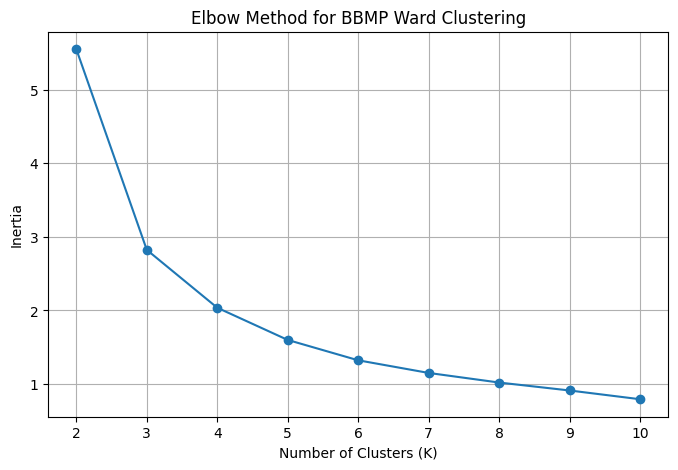

In [30]:
#plot the elbow method

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for BBMP Ward Clustering")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [31]:
#compare silhoutte scores

silhouette_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_features)

    score = silhouette_score(
        scaled_features,
        labels
    )

    silhouette_results.append({
        "K": k,
        "Silhouette_Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

,K,Silhouette_Score
0,2,0.987774
1,3,0.703124
2,4,0.537188
3,5,0.350943
4,6,0.370637
5,7,0.359550
6,8,0.342383
7,9,0.353247
8,10,0.367044


In [32]:
#choose K and train the model

chosen_k = 3  # Change this if your analysis supports another K.

final_kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

clustering_df["Cluster"] = final_kmeans.fit_predict(
    scaled_features
)

display(clustering_df.head())

,Ward Name,Lakes #,Playgrounds #,Govt Schools #,Cluster
0,Kempegowda Ward,2,0,4,0
1,Chowdeswari Ward,2,0,6,0
2,Atturu,2,4,7,0
3,Yelahanka Satellite Town,2,2,4,0
4,Jakkuru,10,1,14,2


In [33]:
#count wards in each cluster

cluster_counts = (
    clustering_df["Cluster"]
    .value_counts()
    .sort_index()
)

print(cluster_counts)

Cluster
0    185
1      1
2     13
Name: count, dtype: int64


In [34]:
# Compare public-goods averages across clusters

cluster_profile = (
    clustering_df
    .groupby("Cluster")[feature_columns]
    .mean()
    .round(2)
)

display(cluster_profile)

,Lakes #,Playgrounds #,Govt Schools #
Cluster,,,
0,0.55,1.91,3.22
1,192.00,390.00,684.00
2,6.92,2.77,6.77


In [35]:
#save the clustering results

clustering_output_path = os.path.join(
    bbmp_processed_path,
    "bbmp_ward_cluster_results.csv"
)

clustering_df.to_csv(
    clustering_output_path,
    index=False
)

cluster_profile.to_csv(
    os.path.join(
        bbmp_processed_path,
        "bbmp_cluster_profile.csv"
    )
)

print("Clustering results saved!")

Clustering results saved!


## BBMP Ward Clustering — Findings

1. Number of clusters selected:
2. Reason for selecting this K:
3. Cluster 0 characteristics:
4. Cluster 1 characteristics:
5. Cluster 2 characteristics:
6. Key observation:

The clusters represent groups of wards with similar
public-goods characteristics. They do not automatically
represent overall ward quality.

In [37]:
#identify wards in each cluster

for cluster_number in sorted(clustering_df["Cluster"].unique()):
    print(f"\nCluster {cluster_number}")

    display(
        clustering_df.loc[
            clustering_df["Cluster"] == cluster_number,
            [ward_column] + feature_columns
        ]
    )


Cluster 0


,Ward Name,Lakes #,Playgrounds #,Govt Schools #
0,Kempegowda Ward,2,0,4
1,Chowdeswari Ward,2,0,6
2,Atturu,2,4,7
3,Yelahanka Satellite Town,2,2,4
5,Thanisandra,1,1,9
...,...,...,...,...
189,Mangammana Palya,3,0,4
192,Arakere,3,4,4
193,Gottigere,3,2,2
194,Konankunte,1,3,9



Cluster 1


,Ward Name,Lakes #,Playgrounds #,Govt Schools #
198,Total,192,390,684



Cluster 2


,Ward Name,Lakes #,Playgrounds #,Govt Schools #
4,Jakkuru,10,1,14
24,Horamavu,5,3,13
54,Devasandra,4,0,6
81,Garudachar palya,4,0,6
84,Dodda Nekkundi,5,3,0
148,Varthur,7,0,11
149,Bellanduru,11,0,3
159,Raja Rajeshawari Nagar,6,10,2
183,Uttarahalli,5,4,2
190,Singa Sandra,6,1,12


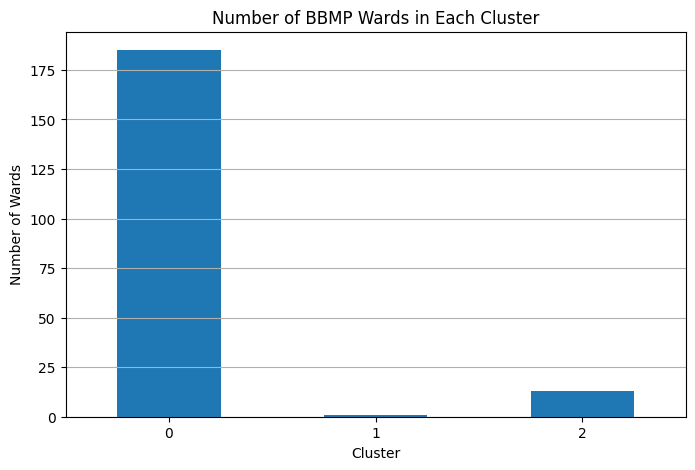

In [38]:
#visualise the cluster sizes

plt.figure(figsize=(8, 5))

cluster_counts.plot(kind="bar")

plt.title("Number of BBMP Wards in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Wards")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

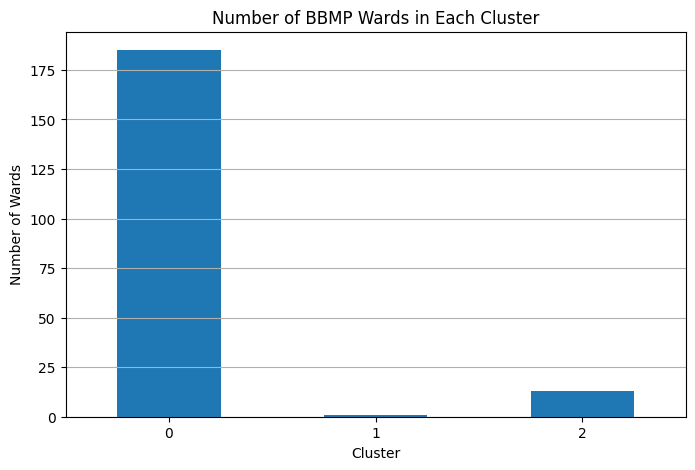

In [39]:
#save the cluster visualization

plt.figure(figsize=(8, 5))

cluster_counts.plot(kind="bar")

plt.title("Number of BBMP Wards in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Wards")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.savefig(
    os.path.join(
        bbmp_processed_path,
        "bbmp_cluster_distribution.png"
    ),
    bbox_inches="tight"
)

plt.show()


## Limitations

- Clustering depends on the selected public-goods features.
- Standardisation changes the scale of the original measurements.
- K-means requires choosing the number of clusters.
- Cluster membership indicates similarity, not causation.
- The dataset may not represent every aspect of public infrastructure.## Limitations

- Clustering depends on the selected public-goods features.
- Standardisation changes the scale of the original measurements.
- K-means requires choosing the number of clusters.
- Cluster membership indicates similarity, not causation.
- The dataset may not represent every aspect of public infrastructure.

In [40]:
print("BBMP processed files:")

for file in os.listdir(bbmp_processed_path):
    print(file)

BBMP processed files:
bbmp_inspection_report.csv
bbmp_ward_cluster_results.csv
bbmp_cluster_profile.csv
bbmp_cluster_distribution.png
